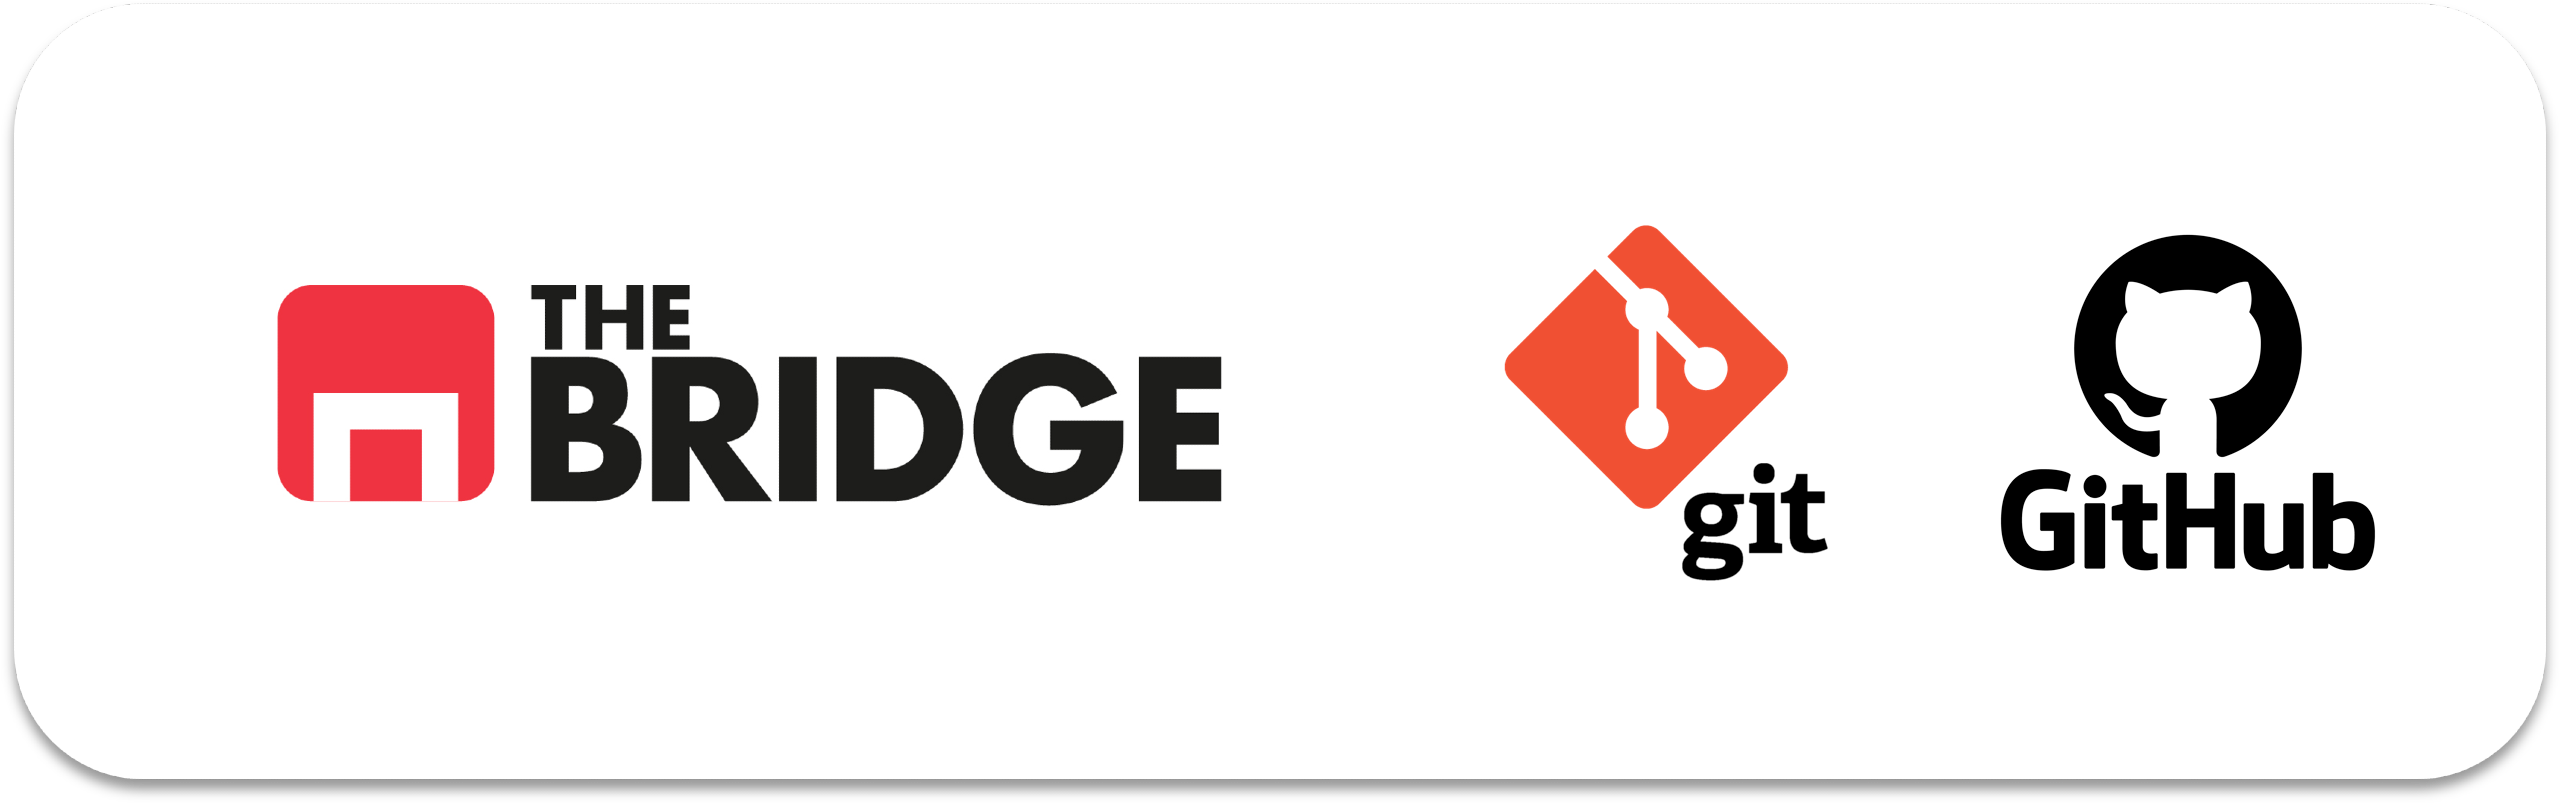

<div align="center">

# 🌿 Git & GitHub Masterclass

**Lo mínimo para trabajar en equipo en el bootcamp**

*Versión revisada · noviembre 2026 · alineada con el Gitflow de los Team Challenges*

</div>

---

## Índice
0. [Antes de la sesión (pre-work obligatorio)](#0-prework)
1. [¿Qué es Git?](#1-intro)
2. [Primeros comandos](#2-comandos)
3. [Ramas, merge y conflictos](#3-ramas)
4. [GitHub: subir, bajar y Pull Requests](#4-github)
5. [El flujo de ramas de los Team Challenges](#5-flujo)
6. [Buenas prácticas](#6-commits)
7. [Chuleta de comandos](#7-ref)
8. [Ampliación (opcional, no entra en la sesión)](#8-ampliacion)
9. [Enlaces de interés](#9-enlaces)

> 📌 Objetivo: salir de la sesión sabiendo hacer commit, crear ramas, resolver un conflicto sencillo, subir a GitHub y abrir una Pull Request hacia `develop`. La sección *Ampliación* es opcional.

---
<a id="0-prework"></a>
## 0. Antes de la sesión (pre-work obligatorio)

En la sesión no hay tiempo para instalar nada. **Haz esto antes**; al empezar solo comprobaremos que funciona.

1. Instala **Git** (en Windows, Git for Windows, que incluye Git Bash) y **VS Code**.
2. Crea una cuenta en [github.com](https://github.com).
3. Instala **GitHub CLI** desde [cli.github.com](https://cli.github.com) y conéctalo con tu cuenta:

```bash
gh auth login          # elige: GitHub.com → HTTPS → Login with a web browser
gh auth status         # debe decir "Logged in to github.com"
```

4. Copia y pega este bloque en la terminal (cambia nombre y email):

```bash
git config --global user.name "Tu Nombre"
git config --global user.email "tu@email.com"
git config --global init.defaultBranch main
git config --global pull.rebase false
git config --global push.autoSetupRemote true
git config --global core.editor "code --wait"
git config --global alias.lg "log --oneline --graph --all --decorate"
```

5. Comprueba con `git --version` y `git config --global --list`.

> **Nota:** No hace falta entender cada línea todavía. En resumen: tu nombre en los commits, la rama principal se llama `main`, `git pull` funciona igual que en los Team Challenges, `git push` es más sencillo, VS Code es el editor y `git lg` dibuja el árbol de ramas.

---
<a id="1-intro"></a>
## 1. ¿Qué es Git?

Git es un **sistema de control de versiones**: guarda el historial de tu proyecto para que puedas volver atrás y trabajar en equipo sin pisaros.

> **Nota:** **Git ≠ GitHub.** Git es el programa que usas en tu ordenador. GitHub es la web donde se guarda una copia del proyecto para compartirla con el equipo.

### Las tres zonas

```text
Tus archivos  ──git add──▶  Staging (preparado)  ──git commit──▶  Historial (.git)
```

- **Repositorio**: la carpeta que Git vigila. La historia vive en la carpeta oculta `.git/`.
- **Commit**: una foto del proyecto en un momento, con un mensaje que explica qué cambió.
- **Staging**: la "sala de espera" donde eliges qué cambios entran en el próximo commit.

---
<a id="2-comandos"></a>
## 2. Primeros comandos

```bash
git init                    # convierte la carpeta en un repositorio
git status                  # ¿qué ha cambiado? (úsalo todo el rato)
git add archivo.txt         # prepara un archivo
git add .                   # prepara todos los cambios
git commit -m "mensaje"     # guarda la foto
git lg                      # ver el historial como un árbol
```

### .gitignore

Lista de archivos que Git **nunca** debe guardar. Créalo al principio. Para proyectos de Python e IA, como mínimo:

```bash
.env
venv/
.venv/
__pycache__/
.ipynb_checkpoints/
```

> **Importante:** Tus claves de API (OpenAI, Gemini, TMDB...) van en `.env` y **nunca** se suben a GitHub. Si una clave se sube por error, hay que anularla y crear otra: borrar el commit no basta.

### Deshacer lo más habitual

| Quiero... | Comando |
|---|---|
| Descartar los cambios de un archivo | `git restore archivo.txt` |
| Sacar un archivo del staging | `git restore --staged archivo.txt` |
| Deshacer un commit que ya está en GitHub | `git revert <hash>` (crea un commit que lo deshace) |

> **Tip:** Si te lías, para y pregunta antes de probar comandos que encuentres por internet como `reset --hard`. Casi todo tiene arreglo si no se borra nada.

### Ejercicio 1 · Tu primer repositorio

1. Crea una carpeta `mi-proyecto`, entra en ella y ejecuta `git init`.
2. Crea un `.gitignore` con la línea `.env`.
3. Crea `README.md` con una frase y un archivo `.env` con `API_KEY=123`.
4. Ejecuta `git status`: aparece `README.md`, pero **no** `.env`.
5. `git add .` y `git commit -m "chore: estructura inicial"`.
6. Mira el resultado con `git lg`.

---
<a id="3-ramas"></a>
## 3. Ramas, merge y conflictos

Una **rama** es una línea de trabajo paralela: puedes probar cosas sin tocar la versión buena. Al terminar, se **fusiona** (*merge*) con la rama principal.

```text
main:      A ── B ── C ─────────── F
                      \           /
feature:               D ── E ───┘
```

```bash
git switch -c feature/login   # crea una rama y te mueve a ella
git switch main               # cambia a otra rama
git merge feature/login       # trae los cambios de feature/login a la rama en la que estás
git branch -d feature/login   # borra la rama cuando ya está fusionada
```

> **Nota:** En tutoriales antiguos verás `git checkout`. Hace lo mismo, pero hoy se usa `git switch` porque es más claro.

### Conflictos

Hay conflicto cuando dos ramas cambian **la misma línea**. Git no elige por ti y marca el archivo:

```text
<<<<<<< HEAD
lo que hay en tu rama
=======
lo que viene de la otra rama
>>>>>>> feature/login
```

Para resolverlo:

1. Abre el archivo en VS Code y pulsa **Resolve in Merge Editor** (o edítalo a mano y borra las marcas `<<<<<<<`, `=======`, `>>>>>>>`).
2. Deja el contenido correcto y guarda.
3. `git add archivo` y `git commit --no-edit`.

> **Tip:** Un conflicto no es un error: es Git preguntándote qué versión quieres. Si te bloqueas, `git merge --abort` deja todo como estaba antes del merge.

### Ejercicio 2 · Ramas Patronus (con conflicto a propósito)

1. Crea la carpeta `Patronus`, ejecuta `git init`, crea `patronus.txt` vacío y haz un commit.
2. Crea dos ramas: `git branch harry` y `git branch snape`.
3. `git switch harry`, luego `echo "PATRONUS: ciervo" > patronus.txt` y commit `"feat: patronus de Harry"`.
4. `git switch snape`, luego `echo "PATRONUS: cierva" > patronus.txt` y commit `"feat: patronus de Snape"`.
5. Mira el árbol con `git lg`: dos ramas salen del mismo commit.
6. `git switch main` y `git merge harry`. Sin problemas.
7. `git merge snape`: **conflicto**, porque las dos ramas cambiaron la misma línea.
8. Resuélvelo en VS Code dejando las dos líneas, y después `git add patronus.txt` y `git commit --no-edit`.
9. `git lg` para ver el merge, y `git branch -d harry snape`.

---
<a id="4-github"></a>
## 4. GitHub: subir, bajar y Pull Requests

```bash
git clone <url>          # descarga un repo de GitHub a tu ordenador
git push                 # sube tus commits de la rama actual
git pull                 # baja los cambios de los demás a la rama actual
```

- `origin` es el nombre que Git da al repositorio de GitHub.
- La primera vez que haces `git push` en una rama nueva, se crea también en GitHub.

### Pull Request (PR)

Una **PR** es la forma de pedir: "revisad mi rama y, si está bien, fusionadla". En los Team Challenges **todo** entra por PR.

1. Subes tu rama con `git push`.
2. Abres la PR en GitHub (botón *Compare & pull request*) o con `gh pr create --base develop --fill`.
3. **Comprueba que la base es `develop`**: GitHub propone `main` por defecto.
4. Un compañero la revisa en *Files changed* y la aprueba.
5. Se fusiona con el botón verde y se borra la rama.

### Ejercicio 3 · Subir tu proyecto a GitHub

1. Dentro de `mi-proyecto` (Ejercicio 1): `gh repo create mi-proyecto --public --source=. --push`.
2. Abre el repo en GitHub y comprueba que **no** está `.env`.
3. Edita `README.md` en la web de GitHub y guarda (*Commit changes*).
4. En tu ordenador, `git pull` y comprueba que el cambio ha llegado.

---
<a id="5-flujo"></a>
## 5. El flujo de ramas de los Team Challenges

En los Team Challenges usaréis una versión sencilla de **Gitflow** con tres tipos de rama:

```text
main        ●──────────────────────────────────●   ← versión final (un merge el último día)
            │                                  ↑
develop     ●────────●─────────●─────────●─────┘   ← donde se junta el trabajo del equipo
                     ↑         ↑         ↑
feature/01  ●──●─────┘         │         │         ← una rama por tarea
feature/02       ●──●──●───────┘         │
feature/03                ●──●───────────┘
```

**Cuatro reglas:**

1. Nadie hace commit directo en `main` ni en `develop`.
2. Cada tarea va en su rama `feature/...`, creada desde `develop`.
3. Las features entran en `develop` por PR, con **Squash and merge**.
4. El último día, `develop` entra en `main` con una PR y **Create a merge commit**.

### El día a día, en comandos

```bash
git switch develop && git pull                 # 1. parto de develop actualizado
git switch -c feature/mi-tarea                 # 2. creo mi rama
git add . && git commit -m "feat: lo que hice" # 3. trabajo y hago commits
git push                                       # 4. subo la rama
gh pr create --base develop --fill             # 5. abro la PR hacia develop
# ... un compañero revisa y fusiona con Squash and merge ...
git switch develop && git pull                 # 6. vuelvo a develop actualizado
git branch -D feature/mi-tarea                 # 7. borro mi rama local
```

> **Nota:** ¿Por qué `-D` y no `-d`? Con *Squash and merge*, GitHub junta tus commits en uno nuevo, y Git no reconoce tu rama como fusionada. Es normal.

> **Tip:** Si un compañero ha fusionado algo que necesitas mientras trabajas en tu rama: `git fetch origin` y `git merge origin/develop`.

### ¿Y el Gitflow "completo"?

En empresas con versiones numeradas (v1.0, v1.1...) se añaden dos ramas más. Basta con saber que existen:

| Rama | Para qué |
|---|---|
| `release/*` | Preparar una versión antes de publicarla en `main` |
| `hotfix/*` | Arreglar un error urgente que ya está en `main` |

En los Team Challenges **no** se usan. El profesor lo enseñará en una demo.

### Ejercicio 4 · Ensayo del Team Challenge (en pareja o solo)

1. Persona A: `gh repo create tc-ensayo --public --add-readme --clone` y `cd tc-ensayo`. Añade a la pareja en Settings → Collaborators.
2. Persona A crea `develop` y la sube: `git switch -c develop` y `git push`.
3. Persona B: `git clone <url>`, `cd tc-ensayo` y `git switch develop`.
4. Persona B: `git switch -c feature/saludo`, crea `saludo.txt`, commit y `git push`.
5. Persona B abre la PR con base `develop`: `gh pr create --base develop --fill`.
6. Persona A la revisa en GitHub y la fusiona con **Squash and merge**.
7. Persona B: `git switch develop`, `git pull` y `git branch -D feature/saludo`.
8. Final: una PR de `develop` a `main` fusionada con **Create a merge commit**.

Si lo haces solo, haz los dos papeles.

---
<a id="6-commits"></a>
## 6. Buenas prácticas

### Mensajes de commit (Conventional Commits)

Formato: `tipo: qué has hecho`. En español o en inglés, pero todo el equipo igual.

| Tipo | Cuándo | Ejemplo |
|---|---|---|
| `feat` | Algo nuevo | `feat: función fetch_movie_details` |
| `fix` | Arreglo de un error | `fix: manejar tmdbId nulo` |
| `docs` | Documentación | `docs: instrucciones de claves en README` |
| `refactor` | Reorganizar sin cambiar el resultado | `refactor: extraer el groupby a una función` |
| `chore` | Mantenimiento | `chore: actualizar requirements.txt` |

### Antes de cada `git push`

- [ ] `git status` no muestra nada raro (ni `.env`)
- [ ] Estás en tu rama, no en `main` ni en `develop` (`git branch --show-current`)
- [ ] Si es un notebook: *Restart & Run All* y sin claves en las salidas
- [ ] El mensaje del commit explica qué has hecho

### Notebooks en equipo

Un notebook es un archivo enorme y sus conflictos son muy difíciles de resolver. Por eso en los Team Challenges **cada notebook lo edita una sola persona**.

---
<a id="7-ref"></a>
## 7. Chuleta de comandos

```bash
# Básico
git status                        # qué ha cambiado
git add .                         # preparar todo
git commit -m "feat: mensaje"     # guardar
git lg                            # ver el árbol

# Ramas
git switch -c feature/mi-tarea    # crear rama y moverme
git switch develop                # cambiar de rama
git merge <rama>                  # fusionar en la rama actual
git branch -D <rama>              # borrar rama local

# GitHub
git clone <url>                   # descargar repo
git pull                          # bajar cambios
git push                          # subir cambios
gh pr create --base develop --fill    # abrir PR hacia develop

# Si algo sale mal
git restore <archivo>             # descartar cambios de un archivo
git merge --abort                 # cancelar un merge con conflictos
```

---
<a id="8-ampliacion"></a>
## 8. Ampliación (opcional, no entra en la sesión)

Nada de esta sección es necesario para los Team Challenges. Está aquí para quien quiera ir más allá.

| Comando | Para qué |
|---|---|
| `git reflog` | Ver todos los movimientos de HEAD y recuperar commits "perdidos" tras un `reset` |
| `git stash push -m "msg"` / `git stash pop` | Guardar trabajo a medias sin hacer commit |
| `git commit --amend` + `git push --force-with-lease` | Rehacer el último commit de **tu** rama (nunca en `main`/`develop`) |
| `git diff main...develop` | Ver lo que `develop` trae respecto a `main` |
| `git tag -a v1.0.0 -m "..."` + `git push --follow-tags` | Marcar versiones |
| `gh repo fork AUTOR/repo --clone` | Contribuir a un proyecto ajeno |
| `git restore --ours/--theirs archivo` | En un conflicto, quedarse entera con una de las versiones |
| `nbdime` (`pip install nbdime`) | Ver diffs legibles de notebooks |

### Ejercicio opcional · Gitflow completo en local

Reproduce en una carpeta `tienda-online` el ciclo completo: `feature/productos` → `develop` → `release/1.0.0` → `main` (tag `v1.0.0`) → hotfix `1.0.1` desde `main` → `feature/carrito` → `release/1.1.0`. Usa `git merge --no-ff` en todos los merges para ver el grafo. La solución está en `scripts/demo_gitflow.sh` (ejecútalo y compara con tu `git lg`).

---
<a id="9-enlaces"></a>
## 9. Enlaces de interés

- [Learn Git Branching](https://learngitbranching.js.org/?locale=es_ES): practica ramas de forma visual en el navegador.
- [Pro Git](https://git-scm.com/book/es/v2): el libro oficial, gratis y en español.
- [Conventional Commits](https://www.conventionalcommits.org/es/v1.0.0/).
- [How to Write a Git Commit Message](https://cbea.ms/git-commit/).